# 11-2. CRPS · MSE · 커버리지 순위 합산 비교 (16개 조합)

`11-1`의 16개 조합을 CRPS, MSE, 90% 커버리지로 비교하고 세 순위를 합산한다(참고용). 순위는 CRPS·MSE는 낮을수록, 커버리지는 90%에 가까울수록 높다.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

res = pd.read_pickle("../cache/cache_107_rank_compare_df.pkl")          # 11-1의 CRPS 계산 결과
per = res.groupby(["모델", "스케일", "구간", "origin"])[["crps7", "crps_ensemble"]].mean()
tab = per.groupby(["모델", "스케일", "구간"]).mean()                      # 16개 조합 평균 CRPS
print(len(tab), "개 조합")

16 개 조합


## 1. 16개 전체 -- CRPS, MSE, 커버리지

In [2]:
rows = []
for (m, sc, g), r in tab.iterrows():
    d = res[(res["모델"] == m) & (res["스케일"] == sc) & (res["구간"] == g)]
    rows.append({"모델": m, "스케일": sc, "구간": g, "crps_ensemble": r["crps_ensemble"], "crps7": r["crps7"], "MSE": d["MSE"].mean(), "커버리지(%)": d["적중"].mean()})
all16 = pd.DataFrame(rows).set_index(["모델", "스케일", "구간"])
all16["순위 crps_ensemble"] = all16["crps_ensemble"].rank().astype(int)
all16["순위 crps7"] = all16["crps7"].rank().astype(int)
all16["순위 MSE"] = all16["MSE"].rank(method="min").astype(int)
all16["순위 커버리지"] = (all16["커버리지(%)"] - 90).abs().rank().astype(int)
all16 = all16.sort_values("crps_ensemble")
display(all16.round(4))

,,,crps_ensemble,crps7,MSE,커버리지(%),순위 crps_ensemble,순위 crps7,순위 MSE,순위 커버리지
모델,스케일,구간,,,,,,,,
SV,원,자체,0.5783,0.5894,1.0526,64.7727,1,2,1,14
GARCH,원,자체,0.5795,0.5892,1.0674,75.0000,2,1,7,6
AR단독,원,자체,0.5931,0.6017,1.1274,65.9091,3,5,9,13
SV,로그,자체,0.5950,0.6164,1.0533,72.7273,4,6,3,9
auto_arima,원,리샘플링,0.5955,0.5951,1.1640,69.3182,5,3,11,12
AR단독,원,리샘플링,0.5986,0.6002,1.1274,63.6364,6,4,9,15
SV,원,리샘플링,0.5987,0.6178,1.0526,82.9545,7,7,1,4
auto_arima,원,자체,0.6104,0.6210,1.1640,61.3636,8,8,11,16
GARCH,원,리샘플링,0.6248,0.6434,1.0674,84.0909,9,9,7,3


### 1-1. 세 지표 순위와 합산

합산이 작을수록 균형이 좋다.

In [3]:
rk = all16[["순위 crps_ensemble", "순위 MSE", "순위 커버리지"]].copy()
rk["순위 합산"] = rk.sum(axis=1)
rk = rk.sort_values(["순위 합산", "순위 crps_ensemble"])
display(rk)

순위 crps_ensemble  순위 MSE  순위 커버리지  순위 합산
모델         스케일 구간                                            
SV         원   리샘플링                 7       1        4     12
GARCH      원   자체                   2       7        6     15
SV         원   자체                   1       1       14     16
           로그  자체                   4       3        9     16
               리샘플링                12       3        2     17
GARCH      원   리샘플링                 9       7        3     19
           로그  리샘플링                16       5        1     22
               자체                  11       5        8     24
AR단독       원   자체                   3       9       13     25
auto_arima 원   리샘플링                 5      11       12     28
AR단독       로그  자체                  10      13        5     28
           원   리샘플링                 6       9       15     30
auto_arima 원   자체                   8      11       16     35
           로그  자체                  14      15        6     35
AR단독       로그  리샘플링                13      13       11     37
auto_arima 로그  리샘플링                15      15       10     40

### 1-2. 세 지표 막대 그래프 (순위 합산 순)

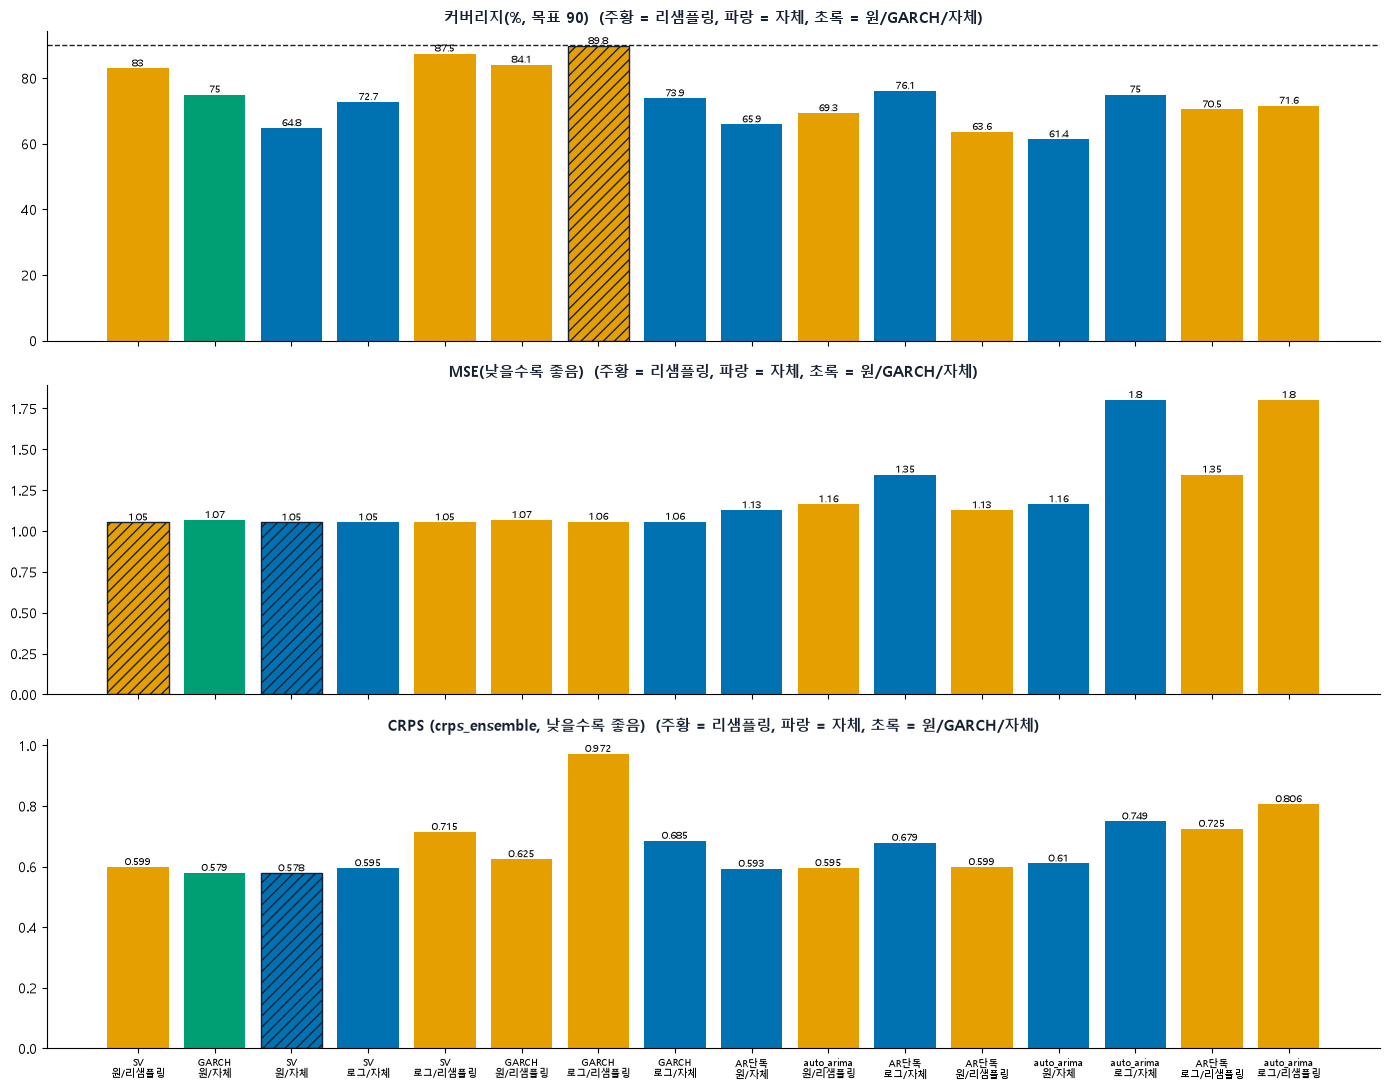

In [4]:
a16 = all16.loc[rk.index]                       # 순위 합산 순서로 정렬
lab = [f"{m}{chr(10)}{sc}/{g}" for m, sc, g in a16.index]
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
for ax, (c, t) in zip(axes, [("커버리지(%)", "커버리지(%, 목표 90)"), ("MSE", "MSE(낮을수록 좋음)"), ("crps_ensemble", "CRPS (crps_ensemble, 낮을수록 좋음)")]):
    v = a16[c].values
    colr = ["#009E73" if (m_, sc2, k) == ("GARCH", "원", "자체") else ("#E69F00" if k == "리샘플링" else "#0072B2") for (m_, sc2, k) in a16.index]   # 원/GARCH/자체만 초록
    bars = ax.bar(range(16), v, color=colr)
    score = np.abs(v - 90) if c.startswith("커버리지") else v
    for b, sc_ in zip(bars, score):
        if sc_ <= score.min() + 1e-9:
            b.set_hatch("///")
            b.set_edgecolor("#172033")
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.3g}", ha="center", va="bottom", fontsize=7)
    if c.startswith("커버리지"):
        ax.axhline(90, color="#172033", linestyle="--", linewidth=1)
    ax.set_title(t + "  (주황 = 리샘플링, 파랑 = 자체, 초록 = 원/GARCH/자체)", fontsize=10.5, fontweight="bold", color="#172033")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[2].set_xticks(range(16))
axes[2].set_xticklabels(lab, fontsize=7)
fig.tight_layout()
plt.show()

### 1-3. CRPS 상위 5개 막대 그래프

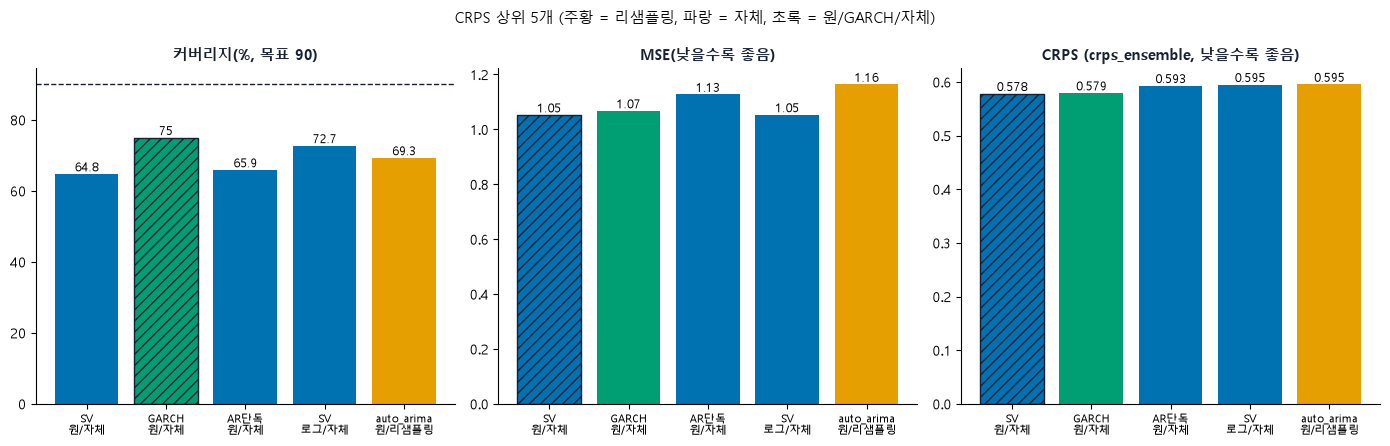

In [5]:
t5 = all16.sort_values("crps_ensemble").head(5)
lab5 = [f"{m}{chr(10)}{sc}/{g}" for m, sc, g in t5.index]
col5 = ["#009E73" if (m_, sc2, k) == ("GARCH", "원", "자체") else ("#E69F00" if k == "리샘플링" else "#0072B2") for (m_, sc2, k) in t5.index]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (c, t) in zip(axes, [("커버리지(%)", "커버리지(%, 목표 90)"), ("MSE", "MSE(낮을수록 좋음)"), ("crps_ensemble", "CRPS (crps_ensemble, 낮을수록 좋음)")]):
    v = t5[c].values
    bars = ax.bar(range(5), v, color=col5)
    score = np.abs(v - 90) if c.startswith("커버리지") else v
    for b, sc_ in zip(bars, score):
        if sc_ <= score.min() + 1e-9:
            b.set_hatch("///")
            b.set_edgecolor("#172033")
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.3g}", ha="center", va="bottom", fontsize=9)
    if c.startswith("커버리지"):
        ax.axhline(90, color="#172033", linestyle="--", linewidth=1)
    ax.set_xticks(range(5))
    ax.set_xticklabels(lab5, fontsize=8)
    ax.set_title(t, fontsize=10.5, fontweight="bold", color="#172033")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.suptitle("CRPS 상위 5개 (주황 = 리샘플링, 파랑 = 자체, 초록 = 원/GARCH/자체)", fontsize=11)
fig.tight_layout()
plt.show()

## 2. 결론

**세 지표를 모두 이기는 조합은 없고, 순위 합산은 SV 원 리샘플링(12)이 가장 작다(다음은 GARCH 원 자체 15).**

- MSE: SV·GARCH가 AR단독·auto_arima보다 낮고 로그에서 격차가 크다(1.05 vs 1.35~1.80).
- 커버리지: 리샘플링(64~90%)이 자체(61~76%)보다 대체로 높고 모두 90% 미만이다.
- 구간을 넓히면 커버리지는 오르고 CRPS는 나빠진다(커버리지 상위 3개의 CRPS 순위는 16, 12, 9위).
- 한계: 22개 origin이 겹치고 유의성 검정은 하지 않았다.